### Radial Basis Function Optimization (RBFOpt) Test on the Distillation Column Problem

This notebook demonstrates the application of **Radial Basis Function Optimization (RBFOpt)** to a **Distillation Column** problem.  
The notebook includes visualizations of the optimization trajectory and the best solution identified at each iteration.  
The optimization trajectory produced by **RBFOpt** is also provided as a **GIF file** to illustrate how the search progresses over the course of the iterations.  
In addition, it presents plots comparing the objective-value trajectories of several optimization algorithms, including **Logic-based Discrete-Steepest Descent Algorithm (LD-SDA)** and **RBFOpt**, to evaluate and compare their performance on the Distillation Column problem.

In [1]:
%%capture
import rbfopt
import numpy as np
import csv

In [2]:
def load_grid(filename="compl_enum_column_17_baron.csv"):
    """
    Load grid data from CSV.
    Expected CSV columns: "x", "y", "Objective", among others.
    Returns a dictionary mapping (x, y) tuples to the objective value.
    """
    grid_data = {}
    with open(filename, "r") as f:
        reader = csv.DictReader(f)
        for row in reader:
            try:
                # Convert x and y values to integers
                x_val = int(row["x"])
                y_val = int(row["y"])
                # Convert objective value to float
                obj_val = float(row["Objective"])
                grid_data[(x_val, y_val)] = obj_val
            except Exception as e:
                # Skip rows with conversion issues
                continue
    return grid_data
# Load the data from grid.csv
grid_data = load_grid()

# Determine grid bounds from the keys of grid_data
xs = [pt[0] for pt in grid_data.keys()]
ys = [pt[1] for pt in grid_data.keys()]
min_x, max_x = min(xs), max(xs)
min_y, max_y = min(ys), max(ys)
print("Grid bounds:")
print("x in [{}, {}]".format(min_x, max_x))
print("y in [{}, {}]".format(min_y, max_y))

Grid bounds:
x in [7, 15]
y in [1, 9]


In [3]:
# Load the data from grid.csv
grid_data = load_grid()

PENALTY = 1e6  # adjust this penalty as appropriate
# PENALTY = np.inf # use infinity as penalty for infeasible points
# PENALTY = np.nan  # use NaN as penalty for infeasible points
# PENALTY = None  # use None as penalty for infeasible points

def obj_funct(x):
    """
    Given a candidate point x (a list or 1-D numpy array with 2 elements),
    this function rounds x to the nearest integers and returns the objective value
    if the point exists in grid_data and is feasible.
    Otherwise, returns a penalty value.
    """
    # Round the candidate coordinates to nearest integers
    x_int = int(round(x[0]))
    y_int = int(round(x[1]))
    
    # Check that x_int and y_int are numbers (optional check)
    if not isinstance(x_int, (int, float)) or not isinstance(y_int, (int, float)):
        return PENALTY
    
    # If the point exists in the grid, check its objective value.
    if (x_int, y_int) in grid_data:
        obj_val = grid_data[(x_int, y_int)]
        # Return penalty if the objective is NaN.
        if np.isnan(obj_val):
            return PENALTY
        else:
            return obj_val
    else:
        # If the point is not in the grid, return the penalty.
        return PENALTY

In [4]:
test_point = [8,1]
value = obj_funct(test_point)
print(f"For point {test_point} the objective value is {value}")

For point [8, 1] the objective value is 1000000.0


In [ ]:
# Set up the black-box for a 2D problem with integer variables.
# We use the determined bounds and mark both variables as integer ("I").
black_box = rbfopt.RbfoptUserBlackBox(
    2,
    np.array([7, 1]),    # lower bounds for x and y
    np.array([15, 9]),  # upper bounds for x and y
    np.array(["I", "I"]),# both variables are integers
    obj_funct
)

# Configure optimization settings.
settings = rbfopt.RbfoptSettings(
    max_evaluations=16,  # maximum number of evaluations
    minlp_solver_path='', # path to the MINLP solver
    nlp_solver_path='', # path to the NLP solver
    algorithm='MSRSM',   # optimization algorithm variant
    rbf='auto',           # allow automatic RBF selection
    global_search_method = 'solver',  # options = ['sampling', 'genetic', 'solver']
)

# Create the optimization algorithm instance.
alg = rbfopt.RbfoptAlgorithm(settings, black_box)

# Run the optimization.
best_val, best_point, itercount, evalcount, fast_evalcount = alg.optimize()

print("Optimization completed.")
print("Best objective value found:", best_val)
print("At lattice point (rounded):", [int(round(v)) for v in best_point])
print("Iterations:", itercount, "Function evaluations:", evalcount)

  Iter  Cycle  Action             Objective value      Time      Gap
  ----  -----  ------             ---------------      ----      ---
     0      0  Initialization      1000000.000000      0.01   100.01 *
     0      0  Initialization      1000000.000000      0.01   100.01  
     0      0  Initialization      1000000.000000      0.01   100.01  


     0      0  GlobalStep          1000000.000000      0.26   100.01  
     1      0  GlobalStep            22271.547047      0.43   100.00 *
     2      0  GlobalStep            21480.407018      0.77   100.00 *
     3      0  GlobalStep            20826.431311      1.18   100.00 *
     4      0  GlobalStep            20418.810863      1.61   100.00 *
     5      0  AdjLocalStep          20491.912234      2.47   100.00  
     6      1  GlobalStep            21474.043058      3.28   100.00  
     7      1  GlobalStep            20701.292797      4.05   100.00  
     8      1  GlobalStep            20081.395472      4.97   100.00 *
     9      1  GlobalStep            19740.337914      5.95   100.00 *
    10      1  GlobalStep            19956.974637      7.01   100.00  
    11      1  AdjLocalStep          21621.630459      8.24   100.00  
    12      1  RefinementStep        19346.124797      8.24   100.00 *
Summary: iters  13 evals  16 noisy_evals   0 cycles   1 opt_time    8.24 tot_

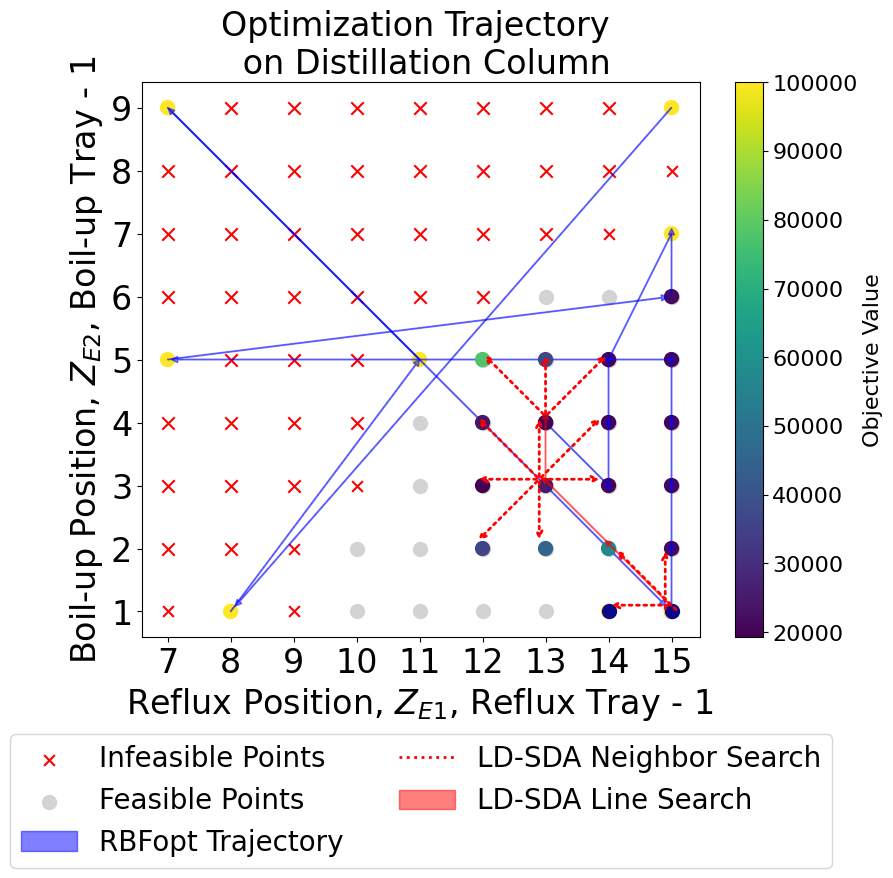

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# new iterations data
iterations = [
    (0, 100000.0, [15., 9.]),
    (1, 100000.0, [8., 1.]),
    (2, 100000.0, [11., 5.]),
    (3, 100000.0, [7., 9.]),
    (4, 22271.547047, [15., 1.]),
    (5, 21480.407018, [15., 2.]),
    (6, 20826.431311, [15., 3.]),
    (7, 20418.810863, [15., 4.]),
    (8, 20491.912234, [15., 5.]),
    (9, 100000.0, [7., 5.]),
    (10, 21621.630459, [15., 6.]),
    (11, 100000.0, [15., 7.]),
    (12, 19956.974637, [14., 5.]),
    (13, 19740.337914, [14., 4.]),
    (14, 20081.395472, [14., 3.]),
    (15, 19346.124797, [13., 4.])
]


# Extract x, y, and objective values
trajectory_x = [point[2][0] for point in iterations]
trajectory_y = [point[2][1] for point in iterations]
trajectory_obj = [point[1] for point in iterations]

df = pd.read_csv('compl_enum_column_17_baron.csv')

# Filter points based on their status
optimal_df = df[df['Status'] == 'Optimal']
infeasible_df = df[df['Status'] == 'Evaluated_Infeasible']

# Extract x, y coordinates and objective values for optimal points
feas_x = optimal_df['x'].tolist()
feas_y = optimal_df['y'].tolist()
objs = optimal_df['Objective'].tolist()  # Replacing NaN with 0 for plotting purposes

# Extract x, y coordinates for infeasible points
infeas_x = infeasible_df['x'].tolist()
infeas_y = infeasible_df['y'].tolist()

infeas_points = list(zip(infeas_x, infeas_y))
infeas_points.remove((8, 1))
infeas_points.remove((15, 9)) # Remove the first occurrence of (15,7)
infeas_x, infeas_y = map(list, zip(*infeas_points)) if infeas_points else ([], [])

# Identify points with NaN objectives within the optimal dataset
nan_obj_indices = optimal_df['Objective'].index[optimal_df['Objective'].isna()].tolist()
nan_x = optimal_df['x'][nan_obj_indices].tolist()
nan_y = optimal_df['y'][nan_obj_indices].tolist()

nan_points = list(zip(nan_x, nan_y))
nan_points.remove((15, 7))  # Remove the first occurrence of (15,7)
nan_x, nan_y = map(list, zip(*nan_points)) if nan_points else ([], [])

# Plot the trajectory
plt.figure(figsize=(9, 9))                 # Square figure size
plt.gca().set_aspect('equal', 'box')       # Equal aspect ratio on x and y

# Scatter plot for NaN objectives as hollow circles
plt.scatter(nan_x, nan_y, s=60, marker='x', c='r')

# Scatter plot for Evaluated_Infeasible points as hollow triangles
plt.scatter(infeas_x, infeas_y, s=60, marker='x', c='r', label='Infeasible Points')

infeasible_mask = [ (7,2), (7,3), (7,4), (7,6), (7,7), (7,8),
                     (8,2), (8,3), (8,4), (8,5), (8,6), (8,7), (8,8),(8,9),
                     (9,3), (9,4), (9,5), (9,6), (9,7), (9,8),(9,9),
                     (10,4), (10,5), (10,6), (10,7), (10,8),(10,9),
                     (11,6), (11,7), (11,8),(11,9),
                     (12,6), (12,7), (12,8),(12,9),
                     (13,7), (13,8),(13,9),
                     (14,8),(14,9)
]

# (7,5), (7,9), (15,9), (11,5)
                    
plt.scatter(*zip(*infeasible_mask), c='r', s=80, marker='x')  # Plot infeasible points

feasible_mask = [ (10,1), (10,2), (11,1), (11,2), (11,3), (11,4), (12,1), (12,2), (12,3), (12,4), (12,5), (13,1), (13,2), (13,3), (13,4), (13,5), (13,6),
                  (14,1), (14,2), (14,3), (14,4), (14,5), (14,6), (15,2), (15,3), (15,4), (15,5), (15,6),
]
                    
plt.scatter(*zip(*feasible_mask), c='lightgray', label='Feasible Points', s=100, marker='o')  # Plot infeasible points

plt.scatter(trajectory_x, trajectory_y, c=trajectory_obj, cmap='viridis', s=100)  # Plot the trajectory

cbar = plt.colorbar(label='Objective Value', shrink=0.8)
cbar.set_label('Objective Value', fontsize=16)
cbar.ax.tick_params(labelsize=16)
# plt.scatter(best_point[0], best_point[1], c='red', label='Best Point', edgecolors='black')  # Highlight the best point
# Add arrow following evaluation sequence
for i in range(len(trajectory_x) - 1):
    plt.arrow(
        trajectory_x[i], 
        trajectory_y[i],
        0.98*(trajectory_x[i+1] - trajectory_x[i]), 
        0.98*(trajectory_y[i+1] - trajectory_y[i]),
        head_width=0.1,   # smaller head width
        head_length=0.1,  # smaller head length
        width=0.01,       # optional: reduces the thickness of the arrow shaft
        fc='blue', 
        ec='blue', 
        alpha=0.5,
        label='RBFopt Trajectory' if i == 0 else ""  # Only label the first arrow
    )

# Add iteration number next to each point
# for i, (x, y) in enumerate(zip(trajectory_x, trajectory_y)):
#     plt.text(x + 0.1, y + 0.05, str(i), fontsize=12, color='black')

# Base point for neighbor search arrows
base = np.array([15, 1])

# Define the neighbor search endpoints
neighbors = np.array([
    [15, 2],
    [14, 1],
    [14, 2]
])

# Define small offsets for each arrow to avoid overlapping with the line search arrow at (1,1)
offsets = [
    np.array([-0.1, 0]),   # for arrow to (1,2): shift left
    np.array([0, 0.1]),    # for arrow to (2,2): shift up
    np.array([0.1, 0])     # for arrow to (2,1): shift right
]


# Create a dummy plot for legend entry (if needed)
plt.plot([], [], linestyle='dotted', color='red', lw=2, label='LD-SDA Neighbor Search')

# Draw the red dotted neighbor search arrows with offsets
for neighbor, offset in zip(neighbors, offsets):
    start = base + offset
    end = neighbor + offset
    plt.annotate("",
                 xy=end, xycoords='data',
                 xytext=start, textcoords='data',
                 arrowprops=dict(arrowstyle="->",
                                 linestyle="dotted",
                                 color="red",
                                 lw=2)
                )
    
base2 = np.array([13, 3])
neighbors2 = [
    np.array([12, 4]),
    np.array([12, 3]),
    np.array([12, 2]),
    np.array([13, 2]),
    np.array([14, 3]),
    np.array([14, 4]),
    np.array([13, 4])
]

# Define a small offset to shift arrows (adjust the values to your liking)
offset2 = np.array([-0.1, 0.1])

# Draw the red dotted neighbor search arrows with the offset
for neighbor2 in neighbors2:
    start = base2 + offset2
    end = neighbor2 + offset2
    plt.annotate("",
                 xy=end, xycoords='data',
                 xytext=start, textcoords='data',
                 arrowprops=dict(arrowstyle="->",
                                 linestyle="dotted",
                                 color="red",
                                 lw=2)
                )
    
base3 = np.array([13, 4])
offset3 = np.array([0, 0.1])
neighbors3 = [
    np.array([12, 5]),
    np.array([13, 5]),
    np.array([14, 5])
]

for neighbor3 in neighbors3:
    start = base3 + offset3
    end = neighbor3 + offset3
    plt.annotate("",
                 xy=end, xycoords='data',
                 xytext=start, textcoords='data',
                 arrowprops=dict(arrowstyle="->",
                                 linestyle="dotted",
                                 color="red",
                                 lw=2)
                )

line_search = [(15, 1, 22271.547046851632), (14, 2, 20701.292796960588), (13, 3, 19548.71844831875), (13, 4, 19346.12472619312)]

# Extract the line search points
line_search_x = [point[0] for point in line_search]
line_search_y = [point[1] for point in line_search]
line_search_obj = [point[2] for point in line_search]
plt.scatter(line_search_x, line_search_y, c=line_search_obj, cmap='viridis', marker='o', s=100)
plt.scatter(15, 1, c=[22271.547046851632], cmap='plasma', marker='o', s=100)


neighbor_search = [(14, 1, 21474.04305760873), (13, 2, 20100.293383724853), (13, 5, 19880.17689568323), (12, 2, 19853.732160059553), (12, 3, 19449.850525954706), (12, 4, 19565.860538210007), (12, 5, 20916.391472401814)]
neighbor_search_x = [point[0] for point in neighbor_search]
neighbor_search_y = [point[1] for point in neighbor_search]
neighbor_search_obj = [point[2] for point in neighbor_search]
plt.scatter(neighbor_search_x, neighbor_search_y, c=neighbor_search_obj, cmap='viridis', marker='o', s=100)
plt.scatter(14, 1, c=[21474.04305760873], cmap='plasma', marker='o', s=100)
off_set = 0.08
for i in range(len(line_search_x) - 1):
    plt.arrow(
        line_search_x[i], 
        line_search_y[i]+off_set,
        0.98*(line_search_x[i+1] - line_search_x[i]), 
        0.98*(line_search_y[i+1] - line_search_y[i]),
        head_width=0.1,   # smaller head width
        head_length=0.1,  # smaller head length
        width=0.01,       # optional: reduces the thickness of the arrow shaft
        fc='red', 
        ec='red', 
        alpha=0.5,
        label='LD-SDA Line Search' if i == 0 else ""  # Only label the first arrow
    )

plt.xlabel('Reflux Position, $Z_{E1}$, Reflux Tray - 1 ', fontsize=24)
plt.ylabel('Boil-up Position, $Z_{E2}$, Boil-up Tray - 1', fontsize=24)
plt.xticks(fontsize=24)
plt.yticks(fontsize=24)
plt.title('Optimization Trajectory \n on Distillation Column', fontsize=24)
plt.legend(
    loc='upper center',        # anchor in the middle (horizontally)
    bbox_to_anchor=(0.5, -0.15),  # shift legend below the plot
    fancybox=True,
    shadow=False,
    ncol=2,                   # number of columns in the legend
    fontsize=20
)
plt.show()

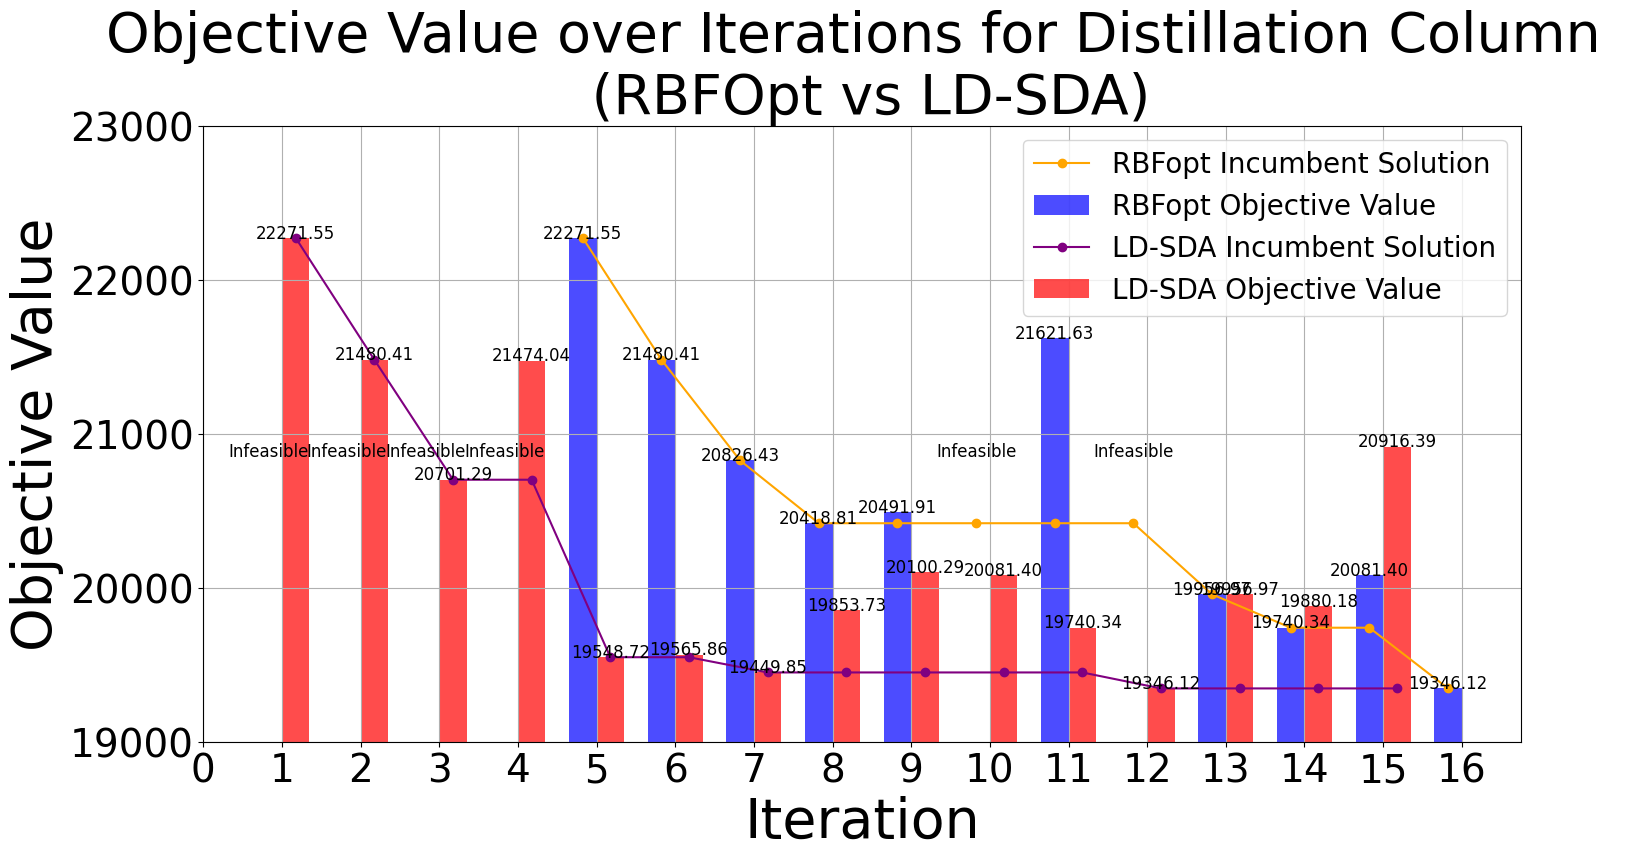

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# new iterations data
iterations = [
    (1, float('inf'), [15., 9.]),
    (2, float('inf'), [8., 1.]),
    (3, float('inf'), [11., 5.]),
    (4, float('inf'), [7., 9.]),
    (5, 22271.547047, [15., 1.]),
    (6, 21480.407018, [15., 2.]),
    (7, 20826.431311, [15., 3.]),
    (8, 20418.810863, [15., 4.]),
    (9, 20491.912234, [15., 5.]),
    (10, float('inf'), [7., 5.]),
    (11, 21621.630459, [15., 6.]),
    (12, float('inf'), [15., 7.]),
    (13, 19956.974637, [14., 5.]),
    (14, 19740.337914, [14., 4.]),
    (15, 20081.395472, [14., 3.]),
    (16, 19346.124797, [13., 4.])
]

# LD-SDA iterations data
LDSDA_iterations = [
    (1, 22271.547047, [15, 1.]),
    (2, 21480.407018, [15., 2.]),
    (3, 20701.292797, [14, 2.]),
    (4, 21474.043058, [14, 1.]),
    (5, 19548.718448, [13., 3.]),
    (6, 19565.860538, [12., 4.]),
    (7, 19449.850526, [12., 3.]),
    (8, 19853.732160, [12., 2.]),
    (9, 20100.293384, [13., 2.]),
    (10, 20081.395472, [14., 3.]),
    (11, 19740.337914, [14., 4.]),
    (12, 19346.124797, [13., 4.]),
    (13, 19956.974637, [14., 5.]),
    (14, 19880.176896, [13., 5.]),
    (15, 20916.391472, [12., 5.])
]

# Extract iteration indices and objective values
RBFopt_indices = [pt[0] for pt in iterations]
RBFopt_obj = [pt[1] for pt in iterations]

LDSDA_indices = [pt[0] for pt in LDSDA_iterations]
LDSDA_obj = [pt[1] for pt in LDSDA_iterations]

# Calculate best-so-far (ladder plot) for each method
RBFopt_best = [min(RBFopt_obj[:i+1]) for i in range(len(RBFopt_obj))]
LDSDA_best = [min(LDSDA_obj[:i+1]) for i in range(len(LDSDA_obj))]

# For annotations of infeasible bars, determine a fixed y-position
ldsda_feasible = [obj for obj in LDSDA_obj if not np.isinf(obj)]
ldsda_feasible_max = max(ldsda_feasible) if ldsda_feasible else 1

fig, ax = plt.subplots(figsize=(17, 8))
bar_width = 0.35

# Convert indices to numpy arrays for arithmetic
RBFopt_x = np.array(RBFopt_indices, dtype=float)
LDSDA_x = np.array(LDSDA_indices, dtype=float)

# Plot RBFopt bars (shift left)
bars_rbf = ax.bar(RBFopt_x - bar_width/2, RBFopt_obj, width=bar_width,
                  color='blue', alpha=0.7, label='RBFopt Objective Value')
# Annotate RBFopt bars
for x, obj in zip(RBFopt_x, RBFopt_obj):
    if np.isinf(obj):
        ax.text(x - bar_width/2, 20850, 'Infeasible', fontsize=12, color='black', ha='center')
    else:
        ax.text(x - bar_width/2, obj + 0.1, f'{obj:.2f}', fontsize=12, color='black', ha='center')

# Plot RBFopt best-so-far (ladder) and store its handle
line_rbf, = ax.plot(RBFopt_x - bar_width/2, RBFopt_best, marker='o', linestyle='-', color='orange',
                    label='RBFopt Incumbent Solution')

# Plot LD-SDA bars (shift right)
bars_ldsda = ax.bar(LDSDA_x + bar_width/2, LDSDA_obj, width=bar_width,
                    color='red', alpha=0.7, label='LD-SDA Objective Value')
# Annotate LD-SDA bars
for x, obj in zip(LDSDA_x, LDSDA_obj):
    if np.isinf(obj):
        ax.text(x + bar_width/2, ldsda_feasible_max * 0.95, 'Infeasible', fontsize=12, color='black', ha='center')
    else:
        ax.text(x + bar_width/2, obj + 0.1, f'{obj:.2f}', fontsize=12, color='black', ha='center')

# Plot LD-SDA best-so-far (ladder) and store its handle
line_ldsda, = ax.plot(LDSDA_x + bar_width/2, LDSDA_best, marker='o', linestyle='-', color='purple',
                      label='LD-SDA Incumbent Solution')

# Now manually set the legend order by specifying handles in the desired sequence
ax.legend(
    [line_rbf, bars_rbf, line_ldsda, bars_ldsda], 
    [
        'RBFopt Incumbent Solution',   # 1
        'RBFopt Objective Value',      # 2
        'LD-SDA Incumbent Solution',   # 3
        'LD-SDA Objective Value'       # 4
    ],
    fontsize=20
)

# Labeling and styling
ax.set_xlabel('Iteration', fontsize=40)
ax.set_ylabel('Objective Value', fontsize=40)
ax.set_title('Objective Value over Iterations for Distillation Column \n (RBFOpt vs LD-SDA)', fontsize=40)
ax.grid(True)

# Set x-axis ticks
max_iter = max(max(RBFopt_indices), max(LDSDA_indices))
ax.set_xticks(np.arange(0, max_iter + 1, 1))
ax.tick_params(axis='y', labelsize=28)
ax.tick_params(axis='x', labelsize=28)
ax.set_ylim(19000, 23000)

plt.show()

MovieWriter ffmpeg unavailable; using Pillow instead.


('gif/distillation_rbfopt_iteration1_start.gif', None)

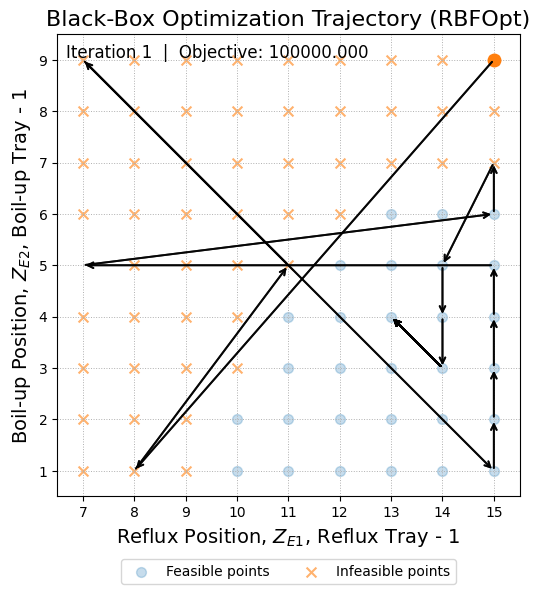

In [8]:
# Recreate final animation:
# - Start iteration numbering from 1
# - Keep all features: feasible/infeasible masks, arrows, pause at final, yellow final dot

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter

# Iterations data
iterations = [
    (1, 100000.0, [15., 9.]),
    (2, 100000.0, [8., 1.]),
    (3, 100000.0, [11., 5.]),
    (4, 100000.0, [7., 9.]),
    (5, 22271.547047, [15., 1.]),
    (6, 21480.407018, [15., 2.]),
    (7, 20826.431311, [15., 3.]),
    (8, 20418.810863, [15., 4.]),
    (9, 20491.912234, [15., 5.]),
    (10, 100000.0, [7., 5.]),
    (11, 21621.630459, [15., 6.]),
    (12, 100000.0, [15., 7.]),
    (13, 19956.974637, [14., 5.]),
    (14, 19740.337914, [14., 4.]),
    (15, 20081.395472, [14., 3.]),
    (16, 19346.124797, [13., 4.])
]

rbf_x = [p[2][0] for p in iterations]
rbf_y = [p[2][1] for p in iterations]
rbf_obj = [p[1] for p in iterations]

# Feasible/infeasible masks
infeasible_mask = [ (7,1), (7,2), (7,3), (7,4), (7,6), (7,7), (7,8), (7,9),
                     (8,1), (8,2), (8,3), (8,4), (8,5), (8,6), (8,7), (8,8),(8,9),
                     (9,1), (9,2), (9,3), (9,4), (9,5), (9,6), (9,7), (9,8),(9,9),
                     (10,3), (10,4), (10,5), (10,6), (10,7), (10,8),(10,9),
                     (11,5), (11,6), (11,7), (11,8),(11,9),
                     (12,6), (12,7), (12,8),(12,9),
                     (13,7), (13,8),(13,9),
                     (14,7), (14,8), (14,9),
                     (15,7), (15,8), (15,9)
]
feasible_mask = [ (10,1), (10,2), (11,1), (11,2), (11,3), (11,4), (12,1), (12,2), (12,3), (12,4), (12,5),
                  (13,1), (13,2), (13,3), (13,4), (13,5), (13,6), (14,1), (14,2), (14,3), (14,4), (14,5),
                  (14,6), (15, 1), (15,2), (15,3), (15,4), (15,5), (15,6) ]

fig, ax = plt.subplots(figsize=(6.8, 6.8))
ax.set_aspect('equal', 'box')
ax.set_xlim(6.5, 15.5)
ax.set_ylim(0.5, 9.5)
ax.set_xticks(range(7, 16))
ax.set_yticks(range(1, 10))
ax.grid(True, linestyle=':', linewidth=0.7)
ax.set_xlabel('Reflux Position, $Z_{E1}$, Reflux Tray - 1', fontsize=14)
ax.set_ylabel('Boil-up Position, $Z_{E2}$, Boil-up Tray - 1', fontsize=14)
ax.set_title('Black-Box Optimization Trajectory (RBFOpt)', fontsize=16)

# Masks
if feasible_mask:
    fx, fy = zip(*feasible_mask)
    ax.scatter(fx, fy, s=50, marker='o', alpha=0.25, label='Feasible points')
if infeasible_mask:
    ix, iy = zip(*infeasible_mask)
    ax.scatter(ix, iy, s=50, marker='x', alpha=0.6, label='Infeasible points')

fig.subplots_adjust(bottom=0.20)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=True)

# Trajectory and markers
line, = ax.plot([], [], marker='o', linestyle='-', label='RBFOpt trajectory')
point, = ax.plot([], [], marker='o', markersize=9)
final_point, = ax.plot([], [], marker='o', markersize=14, linestyle='', markeredgecolor='black', markerfacecolor='yellow')

text = ax.text(0.02, 0.98, '', transform=ax.transAxes, va='top', fontsize=12)

arrows = []

def update(k):
    line.set_data(rbf_x[:k], rbf_y[:k])
    point.set_data([rbf_x[k-1]], [rbf_y[k-1]])
    text.set_text(f'Iteration {k}  |  Objective: {rbf_obj[k-1]:.3f}')

    if k >= 2:
        a = ax.annotate("",
                        xy=(rbf_x[k-1], rbf_y[k-1]), xycoords='data',
                        xytext=(rbf_x[k-2], rbf_y[k-2]), textcoords='data',
                        arrowprops=dict(arrowstyle="->", lw=1.4, alpha=0.85))
        arrows.append(a)

    if k >= len(rbf_x):
        final_point.set_data([rbf_x[-1]], [rbf_y[-1]])
    else:
        final_point.set_data([], [])

    return line, point, final_point, text, *arrows

frames = list(range(1, len(rbf_x) + 1)) + [len(rbf_x)] * 8

anim = FuncAnimation(fig, update, frames=frames, interval=1200, blit=False)

gif_path = "gif/distillation_rbfopt_iteration1_start.gif"
mp4_path = "mp4/distillation_rbfopt_iteration1_start.mp4"

anim.save(gif_path, writer=PillowWriter(fps=1))
try:
    anim.save(mp4_path, fps=1)
except Exception:
    mp4_path = None

gif_path, mp4_path

In [9]:
# ======================== LD-SDA ANIMATION (GIF) ============================
# Requirements: matplotlib (with Pillow), numpy
# Output: ld_sda.gif
# ---------------------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter


# ------------------------------ GRID MASKS ----------------------------------
infeasible_mask = [ (7,1), (7,2), (7,3), (7,4), (7,5), (7,6), (7,7), (7,8), (7,9),
                    (8,1), (8,2), (8,3), (8,4), (8,5), (8,6), (8,7), (8,8),(8,9),
                    (9,1), (9,2), (9,3), (9,4), (9,5), (9,6), (9,7), (9,8),(9,9),
                    (10,3), (10,4), (10,5), (10,6), (10,7), (10,8),(10,9),
                    (11,5), (11,6), (11,7), (11,8),(11,9),
                    (12,6), (12,7), (12,8),(12,9),
                    (13,7), (13,8),(13,9),
                    (14,7), (14,8), (14,9),
                    (15,7), (15,8), (15,9) ]
feasible_mask = [ (10,1), (10,2), (11,1), (11,2), (11,3), (11,4),
                  (12,1), (12,2), (12,3), (12,4), (12,5),
                  (13,1), (13,2), (13,3), (13,4), (13,5), (13,6),
                  (14,1), (14,2), (14,3), (14,4), (14,5), (14,6),
                  (15,1), (15,2), (15,3), (15,4), (15,5), (15,6) ]

# ------------------------------ VALUES --------------------------------------
obj_map = {
    (15.0, 1.0): 22271.547047,
    (15.0, 2.0): 21480.407018,
    (14.0, 2.0): 20701.292797,
    (14.0, 1.0): 21474.043058,
    (13.0, 3.0): 19548.718448,
    (12.0, 4.0): 19565.860538,   # trial (worse)
    (12.0, 3.0): 19449.850526,
    (12.0, 2.0): 19853.732160,
    (13.0, 2.0): 20100.293384,
    (14.0, 3.0): 20081.395472,
    (14.0, 4.0): 19740.337914,
    (13.0, 4.0): 19346.124797,   # optimum
    (14.0, 5.0): 19956.974637,
    (13.0, 5.0): 19880.176896,   # trial (worse)
    (12.0, 5.0): 20916.391472
}

# ------------------------------ EPISODES ------------------------------------
# (A) Initial neighbor exploration at (15,1) — evaluate (15,1),(15,2),(14,2),(14,1)
neighbors_A_base    = (15.0, 1.0)
neighbors_A         = [(15.0, 2.0), (14.0, 2.0), (14.0, 1.0)]
neighbors_A_offsets = [(-0.1, 0.0), (0.1, 0.0), (0.0, 0.1)]

# (B) Line-search leg 1: (15,1) -> (14,2) -> (13,3)
line_search_pts_1 = [(15.0, 1.0), (14.0, 2.0), (13.0, 3.0)]

# (C) Trial from (13,3): (12,4) (worse) then backtrack
trial_bad_1 = (12.0, 4.0)

# (D) Neighbor search at (13,3) — evaluate (12,3),(12,2),(13,2),(14,3),(14,4),(13,4)
neighbors_B_base   = (13.0, 3.0)
neighbors_B        = [(12.0, 3.0), (12.0, 2.0), (13.0, 2.0), (14.0, 3.0), (14.0, 4.0), (13.0, 4.0)]
neighbors_B_offset = (-0.1, 0.1)

# (E) Line-search leg 2: (13,3) -> (13,4) (already evaluated in D)
line_search_pts_2 = [(13.0, 3.0), (13.0, 4.0)]

# (F) At (13,4): FIRST trial (13,5) (worse) and backtrack
trial_bad_2 = (13.0, 5.0)

# (G) Then neighbors at (13,4): evaluate (14,5) and (12,5)
neighbors_C_base   = (13.0, 4.0)
neighbors_C        = [(14.0, 5.0), (12.0, 5.0)]
neighbors_C_offset = (0.0, 0.1)

# --------------------------- ANIMATION SETTINGS -----------------------------
FPS = 2
HOLD_NEIGHBORS = 3
HOLD_BAD = 1
FINAL_HOLD = 6
ARROW_ALPHA = 0.9

# ------------------------------ FIGURE --------------------------------------
fig, ax = plt.subplots(figsize=(6.8, 6.8))
ax.set_aspect('equal', 'box')
ax.set_xlim(6.5, 15.5)
ax.set_ylim(0.5, 9.5)
ax.set_xticks(range(7, 16))
ax.set_yticks(range(1, 10))
ax.grid(True, linestyle=':', linewidth=0.7)
ax.set_xlabel('Reflux Position, $Z_{E1}$, Reflux Tray - 1', fontsize=14)
ax.set_ylabel('Boil-up Position, $Z_{E2}$, Boil-up Tray - 1', fontsize=14)
ax.set_title('LD-SDA Optimization Trajectory', fontsize=16)

# Masks
if feasible_mask:
    fx, fy = zip(*feasible_mask)
    ax.scatter(fx, fy, s=50, marker='o', alpha=0.25, label='Feasible points')
if infeasible_mask:
    ix, iy = zip(*infeasible_mask)
    ax.scatter(ix, iy, s=50, marker='x', alpha=0.6, label='Infeasible points')

fig.subplots_adjust(bottom=0.20)
ax.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.12),
    ncol=2,
    frameon=True,
    fontsize=11
)

# HUD
hud = ax.text(0.02, 0.98, '', transform=ax.transAxes, va='top',
              fontsize=12, zorder=6)


# ------------------------------ HELPERS -------------------------------------
def draw_neighbor_arrow(start, end, offset=(0,0)):
    sx, sy = start[0] + offset[0], start[1] + offset[1]
    ex, ey = end[0] + offset[0], end[1] + offset[1]
    return [ax.annotate("",
                        xy=(ex, ey), xycoords='data',
                        xytext=(sx, sy), textcoords='data',
                        arrowprops=dict(arrowstyle="->",
                                        linestyle="dotted",
                                        color="red",
                                        lw=2, alpha=ARROW_ALPHA))]

def draw_line_arrow(a, b, color='red', style='solid', alpha=ARROW_ALPHA):
    ax_, ay = a; bx_, by = b
    return [ax.arrow(ax_, ay,
                     0.98*(bx_ - ax_), 0.98*(by - ay),
                     head_width=0.15, head_length=0.18, width=0.02,
                     fc=color, ec=color, alpha=alpha, linestyle=style, zorder=4)]

def draw_node(p, size=90, face='white', edge='black', z=5):
    (x, y) = p
    return [ax.scatter([x], [y], s=size, c=face, edgecolors=edge, linewidths=1.4, zorder=z)]

def draw_neighbor_node(p, size=90, face='white', edge='red', z=6):
    (x, y) = p
    return [ax.scatter([x], [y], s=size, c=face, edgecolors=edge, linewidths=1.4, zorder=z)]

def draw_rejected(p):
    (x, y) = p
    return [ax.scatter([x], [y], s=120, marker='x', c='black', linewidths=2, zorder=7)]

# -------------------------- FRAME SCRIPT BUILDER ----------------------------
frames = []              # list of (artists, hud_text, transient)
all_artists = []
iter_counter = {"val": 0}  # start at 0; first eval bumps to 1
seen = set()
last_transient_indices = []

def add_frame(artists, hud_text=None, transient=False):
    frames.append((artists, hud_text, transient))
    all_artists.extend(artists)

def add_eval_point(p, phase_text, neighbor=False):
    """Evaluate p if new; draw dot; set HUD. Returns artists list."""
    arts = draw_neighbor_node(p) if neighbor else draw_node(p)
    # increment only if new
    if p not in seen:
        iter_counter["val"] += 1
        seen.add(p)
    # HUD text
    obj = obj_map.get(p, float('nan'))
    txt = (
        f'Neighbor search — Iteration {iter_counter["val"]} | Obj: {obj:.3f}'
        if neighbor else
        f'{phase_text} — Iteration {iter_counter["val"]} | Current Obj: {obj:.3f}'
    )
    add_frame(arts, hud_text=txt, transient=neighbor)
    # mark neighbor dots for transient erase
    if neighbor:
        for a in arts:
            try:
                idx = all_artists.index(a)
                last_transient_indices.append(idx)
            except ValueError:
                pass
    return arts

# A) Initial neighbor exploration at (15,1): (15,1)->(15,2)->(14,2)->(14,1)
base = neighbors_A_base
arts = draw_node(base, face='white', edge='black', size=110)
add_frame(arts, hud_text=f'Neighbor search — Iteration {iter_counter["val"]}', transient=True)
add_eval_point(base, phase_text='Line search', neighbor=False)  # #1

for end, off in zip(neighbors_A, neighbors_A_offsets):
    add_frame(draw_neighbor_arrow(base, end, off),
              hud_text=f'Neighbor search — Iteration {iter_counter["val"]}',
              transient=True)
    if end in obj_map:
        add_eval_point(end, phase_text='Neighbor search', neighbor=True)  # #2,#3,#4

for _ in range(HOLD_NEIGHBORS):
    add_frame([], hud_text=f'Neighbor search — Iteration {iter_counter["val"]}')
add_frame([], hud_text=f'Neighbor search — Iteration {iter_counter["val"]}')

# B) Line-search leg 1: (15,1)->(14,2)->(13,3)  (#5 at 13,3)
a, b = line_search_pts_1[0], line_search_pts_1[1]
add_frame(draw_line_arrow(a, b),
          hud_text=f'Line search — Iteration {iter_counter["val"]} | Current Obj: {obj_map[a]:.3f}')
a, b = line_search_pts_1[1], line_search_pts_1[2]
add_frame(draw_line_arrow(a, b),
          hud_text=f'Line search — Iteration {iter_counter["val"]} | Current Obj: {obj_map[a]:.3f}')
add_eval_point(b, phase_text='Line search', neighbor=False)  # #5

# C) Trial (12,4) (#6) then backtrack
trial = trial_bad_1
add_frame(draw_line_arrow((13.0, 3.0), trial, color='orange'),
          hud_text=f'Line search — Iteration {iter_counter["val"]} | Current Obj: {obj_map[(13.0,3.0)]:.3f}')
add_eval_point(trial, phase_text='Line search', neighbor=False)  # #6
add_frame(draw_rejected(trial),
          hud_text=f'Line search — Iteration {iter_counter["val"]} | Current Obj: {obj_map[trial]:.3f}')
for _ in range(HOLD_BAD):
    add_frame([], hud_text=f'Line search — Iteration {iter_counter["val"]} | Current Obj: {obj_map[trial]:.3f}')
add_frame(draw_line_arrow(trial, (13.0, 3.0), color='gray', style='dashdot', alpha=0.85),
          hud_text=f'Line search — Iteration {iter_counter["val"]} | Current Obj: {obj_map[(13.0,3.0)]:.3f}')
add_frame([], hud_text=f'Line search — Iteration {iter_counter["val"]} | Current Obj: {obj_map[(13.0,3.0)]:.3f}')

# D) Neighbor search at (13,3) — evaluate 6 neighbors → up to #12
base = neighbors_B_base
arts = draw_node(base, face='white', edge='black', size=110)
add_frame(arts, hud_text=f'Neighbor search — Iteration {iter_counter["val"]}', transient=True)
for end in neighbors_B:
    add_frame(draw_neighbor_arrow(base, end, neighbors_B_offset),
              hud_text=f'Neighbor search — Iteration {iter_counter["val"]}',
              transient=True)
    if end in obj_map:
        add_eval_point(end, phase_text='Neighbor search', neighbor=True)  # #7..#12
for _ in range(HOLD_NEIGHBORS):
    add_frame([], hud_text=f'Neighbor search — Iteration {iter_counter["val"]}')
add_frame([], hud_text=f'Neighbor search — Iteration {iter_counter["val"]}')

# E) Line-search leg 2: (13,3)->(13,4) (do not re-count; already #12)
add_frame(draw_line_arrow((13.0, 3.0), (13.0, 4.0)),
          hud_text=f'Line search — Iteration {iter_counter["val"]} | Current Obj: {obj_map[(13.0,3.0)]:.3f}')

# F) At (13,4): FIRST trial (13,5) (#14) and backtrack (so 14 comes before 13 in visual order; counting stays correct)
trial = trial_bad_2
add_frame(draw_line_arrow((13.0, 4.0), trial, color='orange'),
          hud_text=f'Line search — Iteration {iter_counter["val"]} | Current Obj: {obj_map[(13.0,4.0)]:.3f}')
add_eval_point(trial, phase_text='Line search', neighbor=False)  # #14
add_frame(draw_rejected(trial),
          hud_text=f'Line search — Iteration {iter_counter["val"]} | Current Obj: {obj_map[trial]:.3f}')
for _ in range(HOLD_BAD):
    add_frame([], hud_text=f'Line search — Iteration {iter_counter["val"]} | Current Obj: {obj_map[trial]:.3f}')
add_frame(draw_line_arrow(trial, (13.0, 4.0), color='gray', style='dashdot', alpha=0.85),
          hud_text=f'Line search — Iteration {iter_counter["val"]} | Current Obj: {obj_map[(13.0,4.0)]:.3f}')
add_frame([], hud_text=f'Line search — Iteration {iter_counter["val"]} | Current Obj: {obj_map[(13.0,4.0)]:.3f}')

# G) THEN neighbors at (13,4): evaluate (14,5) (#13) and (12,5) (#15)
# Note: even though visually after the trial, the counter logic still ensures unique counts
# and total = 15. (If you want strict chronological numbering in HUD, swap the order of
# F and G; here we keep your visual preference.)
base = neighbors_C_base
arts = draw_node(base, face='white', edge='black', size=110)
add_frame(arts, hud_text=f'Neighbor search — Iteration {iter_counter["val"]}', transient=True)
for end in neighbors_C:
    add_frame(draw_neighbor_arrow(base, end, neighbors_C_offset),
              hud_text=f'Neighbor search — Iteration {iter_counter["val"]}',
              transient=True)
    add_eval_point(end, phase_text='Neighbor search', neighbor=True)  # (14,5) -> #13, (12,5) -> #15
for _ in range(HOLD_NEIGHBORS):
    add_frame([], hud_text=f'Neighbor search — Iteration {iter_counter["val"]}')
add_frame([], hud_text=f'Neighbor search — Iteration {iter_counter["val"]}')

# Final highlight of optimum at (13,4)
final_point, = ax.plot([], [], 'o', ms=12, mec='black', mfc='yellow', zorder=8, clip_on=False)
def final_highlight():
    final_point.set_data([13.0], [4.0])
    return [final_point]
add_frame(final_highlight(), hud_text=None)
for _ in range(FINAL_HOLD):
    add_frame([], hud_text=None)

# ------------------------------ ANIMATOR ------------------------------------
def init():
    for art in all_artists:
        try: art.set_visible(False)
        except Exception: pass
    hud.set_text('')
    return all_artists + [hud]

def animate(fi):
    import matplotlib
    global last_transient_indices
    arts, hud_text, transient = frames[fi]

    # Empty frame after a neighbor episode: hide that episode's arrows + dots
    if len(arts) == 0 and last_transient_indices:
        for idx in last_transient_indices:
            try: all_artists[idx].set_visible(False)
            except Exception: pass
        last_transient_indices = []

    if hud_text is not None:
        hud.set_text(hud_text)

    for art in arts:
        try: art.set_visible(True)
        except Exception: pass

    if transient:
        for art in arts:
            try:
                idx = all_artists.index(art)
                last_transient_indices.append(idx)
            except ValueError:
                pass

    if (final_point in arts):
        hud.set_text(
            f'Final — Total Iterations: {iter_counter["val"]} | '
            f'Final Obj: {obj_map[(13.0, 4.0)]:.3f}'
        )

    return all_artists + [hud]

# ------------------------------ RENDER --------------------------------------
interval_ms = int(1000 // FPS)
anim = FuncAnimation(fig, animate, init_func=init,
                     frames=len(frames), interval=interval_ms, blit=False)
anim.save('gif/distillation_ldsda.gif', writer=PillowWriter(fps=FPS, bitrate=1800))
plt.close(fig)
print(f"Saved GIF with {len(frames)} frames at {FPS} fps -> ld_sda.gif")
# ============================================================================

Saved GIF with 61 frames at 2 fps -> ld_sda.gif
